# Блок 1. Линейная регрессия
## 1.1 Визуальная регрессия
Прежде чем писать алгоритмы, посмотрим на данные глазами. `sns.regplot()` построит линию регрессии автоматически — это визуальное воплощение линейной регрессии без использования ML-библиотек.

**Цель:** увидеть, как выглядит зависимость пикового онлайна от количества отзывов.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_raw_data, clean_data
from src.config import RANDOM_STATE

sns.set_style("whitegrid")

In [2]:
df = clean_data(load_raw_data())
df_no_giants = df[df['total_reviews'] < 1_000_000].copy()
print('Всего игр:', len(df))
print('Без супер-гигантов:', len(df_no_giants))
df_no_giants[['name', 'total_reviews', '24h_peak_players']].describe()

Всего игр: 916
Без супер-гигантов: 910


,total_reviews,24h_peak_players
count,910.000000,910.000000
mean,57721.050549,4006.514286
std,117515.486541,23210.200539
min,0.000000,0.000000
25%,2904.500000,11.000000
50%,14545.500000,378.500000
75%,54222.750000,1824.000000
max,869480.000000,623941.000000


In [3]:
df[df["release_date"].isna()][["name", "release_date", "release_year"]]

,name,release_date,release_year
689,Assassin’s Creed® IV Black Flag™,NaT,<NA>


In [4]:
print(df.dtypes)
print(df["review_score_pct"].describe())

appid                        int64
name                           str
release_date        datetime64[us]
primary_genre                  str
all_tags                       str
price_usd                  float64
discount_pct                 int64
review_score_pct             Int64
total_reviews                int64
estimated_owners             int64
24h_peak_players             int64
is_free                       bool
release_year                 Int64
dtype: object
count        911.0
mean     82.686059
std      13.167485
min           18.0
25%           76.0
50%           86.0
75%           92.0
max          100.0
Name: review_score_pct, dtype: Float64


<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

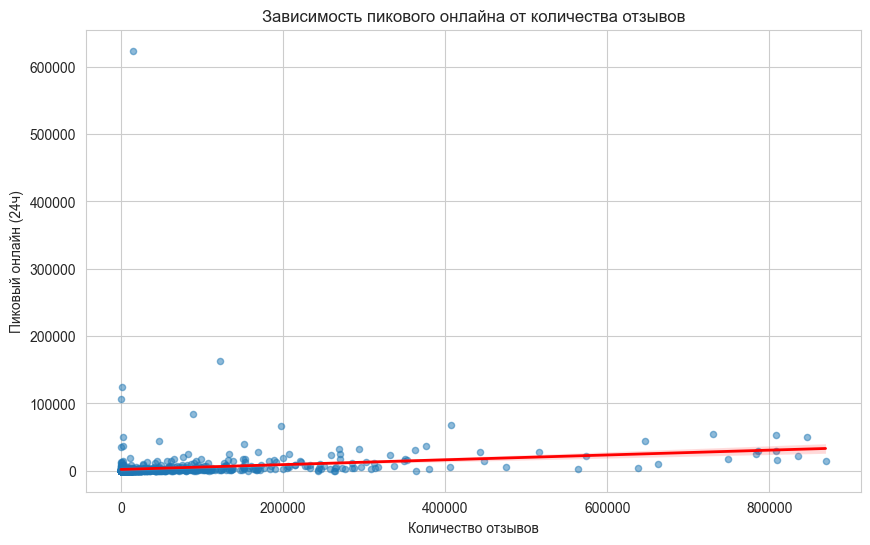

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(
    data=df_no_giants,
    x='total_reviews',
    y='24h_peak_players',
    ax=ax,
    scatter_kws={'alpha': 0.5, 's':20},
    line_kws={'color': 'red', 'linewidth': 2},
)
ax.set_title("Зависимость пикового онлайна от количества отзывов")
ax.set_xlabel("Количество отзывов")
ax.set_ylabel("Пиковый онлайн (24ч)")

plt.tight_layout


### Наблюдения:
1. **Линия почти горизонтальная**. Наклон очень малый относительно масштаба - линейная связь слабая.
2. **Плотное облако точек в левой части.** Большинство игр имеют < 100k отзывов и < 50к онлайна.
3. **Выбросы сверху.** На графике виден ряд точек с онлайном > 200k при небольшом числе отзывов, вероятно могут быть free-to-play гигантами или играми с очень вовлеченной аудиторией.
4. **Ожидание**: $R^2$ будет низким ( <0.5). Возможно, нелинейность связи стоит проверить в следующих блоках.

## 1.2 Подготовка X и y

Для `scikit-learn` требуется:
**X** - признаки в виде двухмерного массива;
**y** - целевая переменная в виде одномерного массива;
отсутствие пропусков. <br>

В линейной регрессии работаем с `total_reviews`. В ней нет пропусков.

In [6]:
# продолжаем на df_no_giants
model_df = df_no_giants.dropna(subset=['total_reviews','24h_peak_players']).copy()
X = model_df[['total_reviews']]
y = model_df['24h_peak_players']
print('Форма Х', X.shape)
print('Форма y', y.shape)
print('\nПервые 5 значений X:')
print(X[:5])
print('\nПервые 5 значений y:')
print(y[:5])

Форма Х (910, 1)
Форма y (910,)

Первые 5 значений X:
   total_reviews
1          49549
3          24360
4          79667
5           2765
6         243810

Первые 5 значений y:
1       0
3       0
4       0
5       0
6    4296
Name: 24h_peak_players, dtype: int64


In [7]:
assert X.isna().sum().sum() == 0, "В Х есть пропуски"
assert y.isna().sum() == 0, "В у есть пропуски"
print("Пропусков нет")

Пропусков нет


In [8]:
print("Игр с 24h_peak_players == 0:", (y == 0).sum(), "из", len(y))
print("Доля:", (y == 0).mean().round(3))

Игр с 24h_peak_players == 0: 220 из 910
Доля: 0.242


## 1.3 Разделение данных

Делим данные на обучающие (train) и валидационные (val).<br>
Пропорции по умолчанию - 75/25.

In [9]:
from sklearn.model_selection import train_test_split
from src.config import RANDOM_STATE

train_X, val_X, train_y, val_y = train_test_split(X, y, random_state=RANDOM_STATE)

print(f'Train X: {train_X.shape}| Train y: {train_y.shape}')
print(f'Val X: {val_X.shape}| Val y: {val_y.shape}')

Train X: (682, 1)| Train y: (682,)
Val X: (228, 1)| Val y: (228,)


## 1.4 Обучение и оценка LinearRegression

Обучаем модель и оцениваем через метрики: MAE и $R^2$

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

model = LinearRegression()
model.fit(train_X, train_y)

# Коэффициенты уравнения
print(f'Коэффициент (наклон): {model.coef_[0]}')
print(f'Intercept (сдвиг): {model.intercept_}')
print(f'Уравнение: y = {model.coef_[0]:.4f} * total_reviews + {model.intercept_:.4f}')

# Прогнозирование
train_pred = model.predict(train_X)
val_pred = model.predict(val_X)

# Метрики
mae_train = mean_absolute_error(train_y, train_pred)
mae_val = mean_absolute_error(val_y, val_pred)
r2_val = r2_score(val_y, val_pred)

print(f'\nMAE (train): {mae_train:.2f}')
print(f'MAE (val): {mae_val:.2f}')
print(f'R² (val): {r2_val:.4f}')

Коэффициент (наклон): 0.03894194228074364
Intercept (сдвиг): 1068.4978435356652
Уравнение: y = 0.0389 * total_reviews + 1068.4978

MAE (train): 3251.60
MAE (val): 6315.09
R² (val): 0.0005


## 1.5  Кросс-валидация

In [14]:
from sklearn.model_selection import cross_val_score

cv_scores = -cross_val_score(LinearRegression(), X, y, cv=5, scoring='neg_mean_squared_error')

print(f'MAE по фолдам: {cv_scores.round(2)}')
print(f'Средний MAE (CV): {cv_scores.mean():.2f} ± {cv_scores.std():.2f}')
print(f'MAE на val: {mae_val:.2f}')

MAE по фолдам: [3.79504376e+08 2.19763475e+09 3.34331710e+07 1.13517877e+07
 9.90942215e+06]
Средний MAE (CV): 526366701.09 ± 847308371.01
MAE на val: 6315.09


### Итоги Блока 1

- **Уравнение:** y = 0.0389 * total_reviews + 1068.5
- **R² (val):** 0.0005 — модель практически не объясняет дисперсию.
- **MAE (train):** 3251, **MAE (val):** 6315.
- **Кросс-валидация:** средний MAE = 526 млн — аномалия из-за выбросов (FF XIV с онлайном 623k).

**Вывод:** линейная регрессия не подходит для этих данных. Связь между `total_reviews` и `24h_peak_players`:
1. нелинейная,
2. сильно зашумлена выбросами,
3. требует либо другой модели (дерево), либо трансформации таргета (log).

Это основа, от которой будем отталкиваться далее.

## Дополнительный эксперимент: логарифмирование таргета

**Проблема:** `24h_peak_players` имеет крайне скошенное распределение с экстремальными выбросами (медиана 378, максимум 623k). Линейная регрессия на таких данных работает плохо — выбросы «перетягивают» коэффициенты.

**Решение:** применить `np.log1p()` к таргету. Это сжимает выбросы и делает распределение ближе к нормальному.

**Важно:** после предсказания нужно вернуться в исходную шкалу через `np.expm1()` (обратная операция).

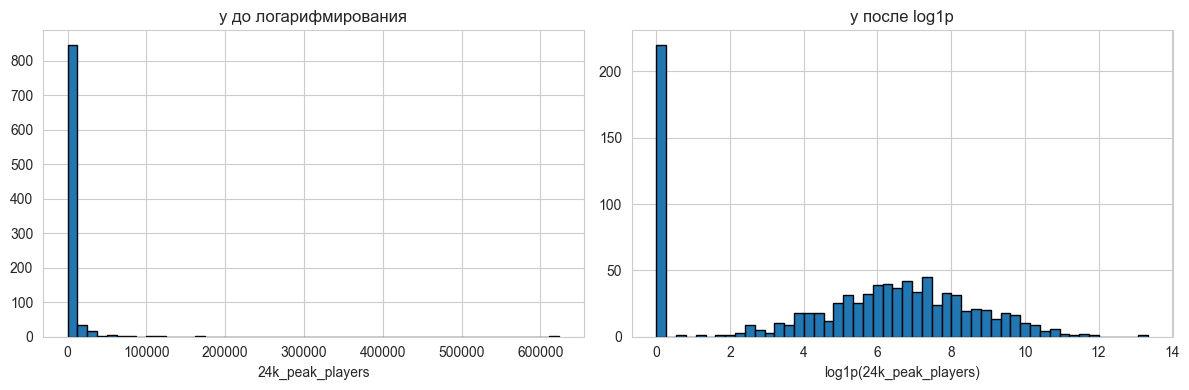

y:  min = 0 | median = 378.5 | max = 623941
y_log: min = 0.0 | median = 5.94 | max = 13.34


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y, bins = 50, edgecolor='black')
axes[0].set_title('y до логарифмирования')
axes[0].set_xlabel('24k_peak_players')

y_log = np.log1p(y)
axes[1].hist(y_log, bins = 50, edgecolor='black')
axes[1].set_title('y после log1p')
axes[1].set_xlabel('log1p(24k_peak_players)')

plt.tight_layout()
plt.show()

print("y:  min =", y.min(), "| median =", y.median(), "| max =", y.max())
print("y_log: min =", y_log.min().round(2), "| median =", y_log.median().round(2), "| max =", y_log.max().round(2))

### Обучение на логарифмированном таргете

Обучаем ту же `LinearRegression`, но на `y_log`. Оценку делаем в **двух шкалах**:
1. В логарифмированной (для сравнения моделей).
2. В исходной (после `expm1`).

In [21]:
train_X_log, val_X_log, train_y_log, val_y_log = train_test_split(
    X, y_log, random_state=RANDOM_STATE
)

model_log = LinearRegression()
model_log.fit(train_X_log, train_y_log)

print("Коэффициент:", model_log.coef_[0].round(4))
print("Intercept:   ", model_log.intercept_.round(4))
print(f"Уравнение: log1p(y) = {model_log.coef_[0]:.6f} * total_reviews + {model_log.intercept_:.4f}")

train_pred_log = model_log.predict(train_X_log)
val_pred_log = model_log.predict(val_X_log)

mae_train_log = mean_absolute_error(train_y_log, train_pred_log)
mae_val_log = mean_absolute_error(val_y_log, val_pred_log)
r2_val_log = r2_score(val_y_log, val_pred_log)

print(f"\n--- Метрики в лог-шкале ---")
print(f"MAE (train): {mae_train_log:.4f}")
print(f"MAE (val):   {mae_val_log:.4f}")
print(f"R² (val):    {r2_val_log:.4f}")

Коэффициент: 0.0
Intercept:    4.3662
Уравнение: log1p(y) = 0.000013 * total_reviews + 4.3662

--- Метрики в лог-шкале ---
MAE (train): 2.4845
MAE (val):   2.5916
R² (val):    0.2043


In [22]:
# Обратное преобразование
train_pred1 = np.expm1(train_pred_log)
val_pred1 = np.expm1(val_pred_log)
# Метрики в исходной шкале
mae_train_orig = mean_absolute_error(train_y, train_pred1)
mae_val_orig = mean_absolute_error(val_y, val_pred1)
r2_val_orig = r2_score(val_y, val_pred1)

print("--- Метрики в исходной шкале ---")
print(f"MAE (train): {mae_train_orig:.2f}")
print(f"MAE (val):   {mae_val_orig:.2f}")
print(f"R² (val):    {r2_val_orig:.4f}")

--- Метрики в исходной шкале ---
MAE (train): 30372.88
MAE (val):   24530.49
R² (val):    -13.5126


In [23]:
cv_scores_log = -cross_val_score(
    LinearRegression(),
    X,
    y_log,
    cv=5,
    scoring="neg_mean_absolute_error",
)

print("MAE по фолдам (лог-шкала):", cv_scores_log.round(3))
print(f"Средний MAE (CV): {cv_scores_log.mean():.3f} ± {cv_scores_log.std():.3f}")

MAE по фолдам (лог-шкала): [3.314 2.552 2.578 2.155 2.024]
Средний MAE (CV): 2.525 ± 0.450


### Эксперимент: log1p(y)

**Что сделали:** применили `np.log1p()` к таргету, обучили ту же LinearRegression.

**Результаты:**

| Метрика | Обычный y | log1p(y) |
|---|---|---|
| CV MAE (среднее) | 526 366 701 | **2.525** |
| CV MAE (std) | 847 308 371 | **0.450** |
| R² (в шкале модели) | 0.0005 | **0.2043** |

**Плюсы:**
- CV перестала «взрываться» — выбросы больше не ломают оценку.
- Разброс по фолдам упал в миллиард раз → модель стабильна.
- R² = 0.20 — уже не ноль.

**Минусы:**
- R² в исходной шкале стал -13.5.
- MAE в исходной шкале вырос с 6315 до 24530.

**Почему R² в исходной шкале отрицательный:**
- Модель обучена в лог-шкале — она минимизирует **относительную** ошибку.
- На гигантах (FF XIV с 623k) она систематически занижает прогноз, и квадратичная метрика (R²) это наказывает.
- В лог-шкале эта же модель работает корректно.

**Вывод:**
Логарифмирование **не улучшает точность в абсолютных числах**, но делает модель **устойчивее** к выбросам. Для skewed-таргетов это стандартный приём.

**Что будет в Блоке 2:**
- Дерево решений — оно должно справиться с нелинейностью лучше, чем линейная модель.
- Вернёмся к вопросу log-трансформации в контексте более сложных моделей.